Assignment 2 xAI

Andrea P. Gómez Jaime


Question 1

1.1

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
import xgboost as xgb
import lime
from shap import TreeExplainer, KernelExplainer
import shap
from lime import lime_tabular
import numpy as np
import matplotlib.pyplot as plt

In [36]:
def split(X, y, n_train=80):
    return X[:n_train], X[n_train:], y[:n_train], y[n_train:]

In [37]:
data = load_breast_cancer()

print(data.data.shape)           # (569, 30): 569 patients, 30 features
print(len(data.feature_names))   # 30
print(data.feature_names)        # the 30 names


(569, 30)
30
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [57]:
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=0)
model = xgb.XGBClassifier()
model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

1.2

LIME

1.2.1

In [58]:
lime_explainer = lime_tabular.LimeTabularExplainer(X_train, training_labels=y_train, mode='classification',
    feature_names=data.feature_names, random_state=0)

attr = np.zeros((len(X_test), X_test.shape[1]))
intercepts = np.zeros(len(X_test))  
for n in range(len(X_test)):
    exp = lime_explainer.explain_instance(X_test[n], model.predict_proba, num_features=30)
    intercepts[n] = exp.intercept[1]
    for j, w in exp.as_map()[1]:
        attr[n, j] = w

global_attr = np.abs(attr).mean(axis=0)     # one value per feature
top10 = np.argsort(global_attr)[::-1][:10]  # then barh, largest first
print(global_attr[top10])
print(top10)

[0.16084246 0.14887954 0.12722387 0.09579238 0.08936466 0.08927446
 0.08415935 0.07242804 0.06369656 0.05448847]
[23 13 21 26 22  7 27  1 15  4]


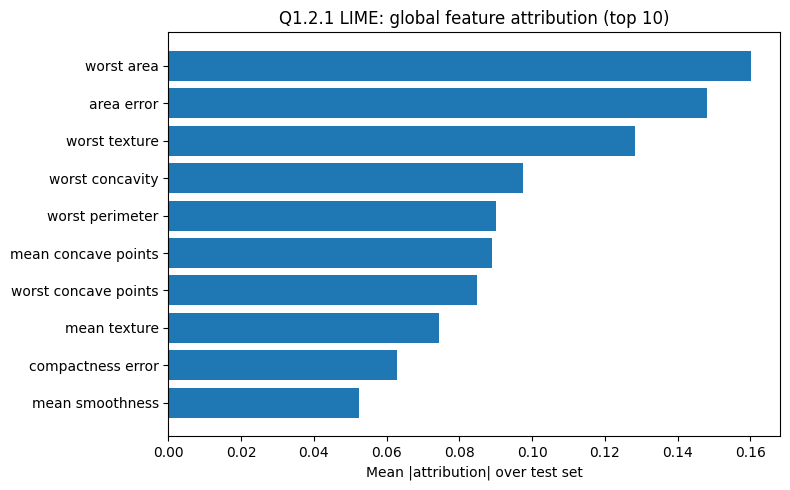

0.9649122807017544


In [69]:
def global_barplot(attr, names, title, k=10):
    global_attr = np.abs(attr).mean(axis=0)              # mean |attribution| per feature
    top = np.argsort(global_attr)[::-1][:k]              # indices, largest first
    plt.figure(figsize=(8, 5))
    plt.barh([names[j] for j in top], global_attr[top])
    plt.gca().invert_yaxis()                             # largest bar on top
    plt.xlabel("Mean |attribution| over test set")
    plt.title(title)
    plt.tight_layout()
    plt.show()

global_barplot(attr, data.feature_names, "Q1.2.1 LIME: global feature attribution (top 10)")
print(model.score(X_test, y_test))


1.2.2

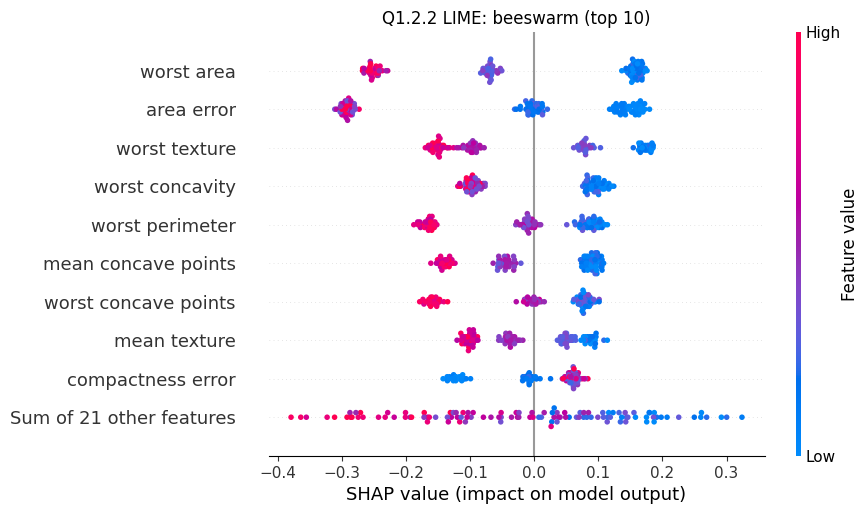

In [60]:
def beeswarm(attr, X, names, title):
    expl = shap.Explanation(values=attr, data=X, feature_names=list(names))
    shap.plots.beeswarm(expl, max_display=10, show=False)
    plt.title(title)
    plt.show()

beeswarm(attr, X_test, data.feature_names, "Q1.2.2 LIME: beeswarm (top 10)")


1.2.3

In [61]:
proba = model.predict_proba(X_test)[:, 1]     # P(class 1) for each test patient
pred = (proba >= 0.5).astype(int)
y = np.asarray(y_test)

def pick(mask, fn):
    idx = np.where(mask)[0]
    return idx[fn(proba[idx])] if len(idx) else None  # None if the cell is empty, returns positions

cases = {
    "True positive (highest P)":  pick((y == 1) & (pred == 1), np.argmax), #returns largest value at returned position
    "True negative (lowest P)":   pick((y == 0) & (pred == 0), np.argmin),
    "False positive (highest P)": pick((y == 0) & (pred == 1), np.argmax),
    "False negative (lowest P)":  pick((y == 1) & (pred == 0), np.argmin),
}
print(cases)

base_lime = intercepts 
intercepts = np.zeros(len(X_test))                 # NEW, before the loop
for n in range(len(X_test)):
    exp = lime_explainer.explain_instance(X_test[n], model.predict_proba, num_features=30)
    intercepts[n] = exp.intercept[1]                  # NEW
    for j, w in exp.as_map()[1]:
        attr[n, j] = w


{'True positive (highest P)': np.int64(9), 'True negative (lowest P)': np.int64(88), 'False positive (highest P)': np.int64(73), 'False negative (lowest P)': np.int64(14)}


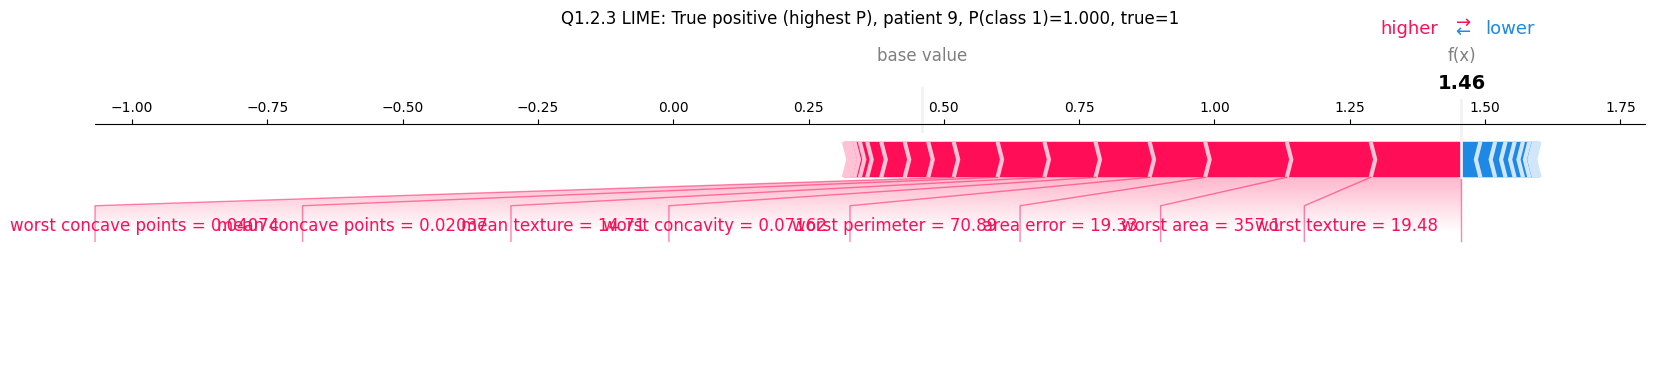

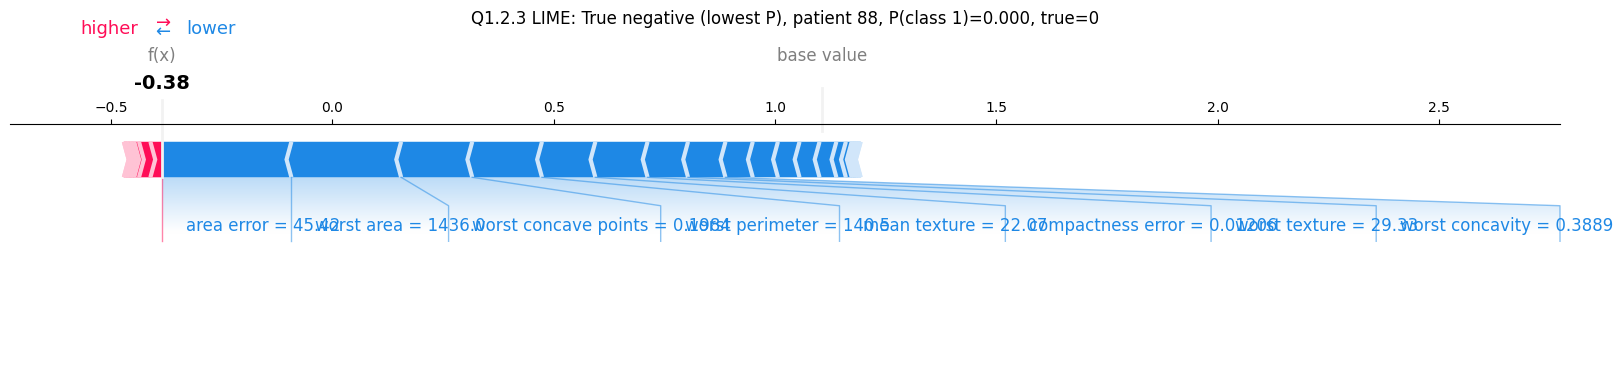

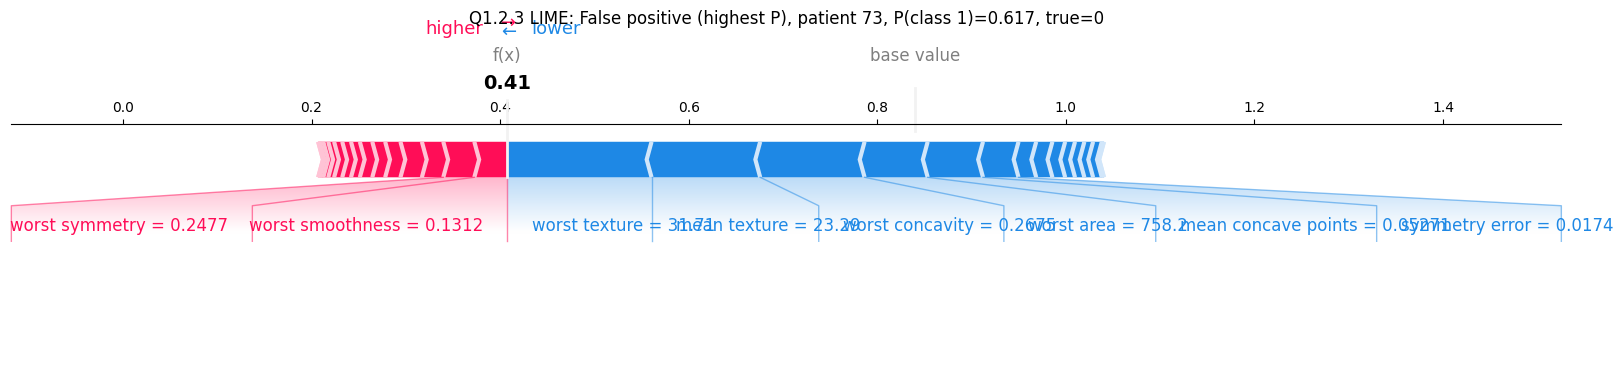

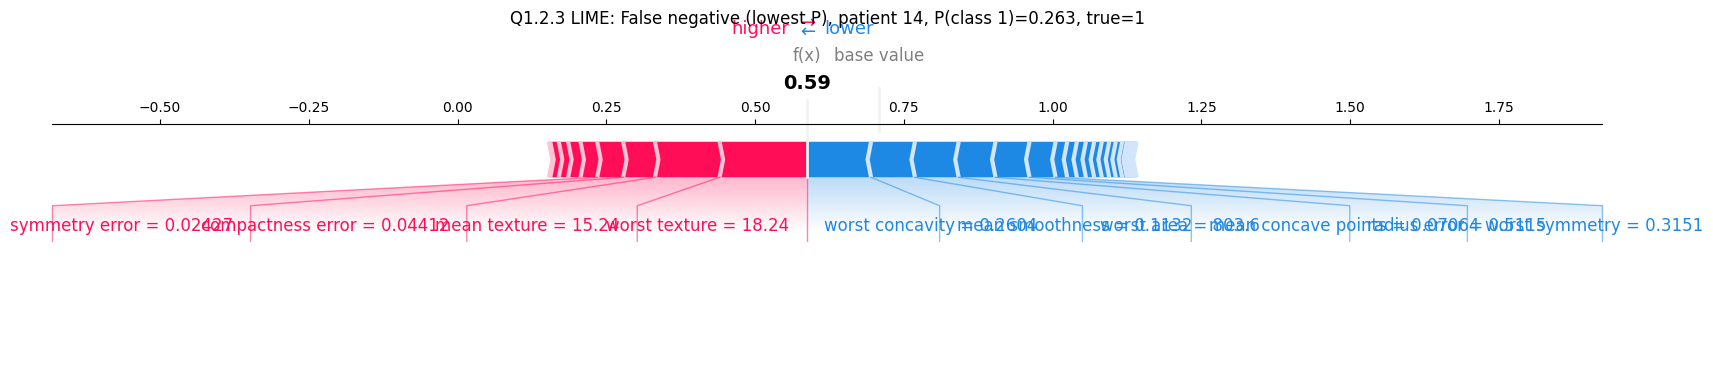

In [62]:
def force_plots(base, attr, X, names, method):
    for label, i in cases.items():
        if i is None:
            print(f"{method}: no example for {label}")
            continue
        b = base[i] if np.ndim(base) else base          # LIME has one base value per patient
        shap.plots.force(b, attr[i], X[i], feature_names=list(names),
                         matplotlib=True, show=False)
        plt.title(f"Q1.2.3 {method}: {label}, patient {i}, "
                  f"P(class 1)={proba[i]:.3f}, true={y[i]}", y=1.4)
        plt.show()

force_plots(base_lime,   attr,   X_test, data.feature_names, "LIME")


KernelSHAP

1.2.1

100%|██████████| 114/114 [00:13<00:00,  8.72it/s]


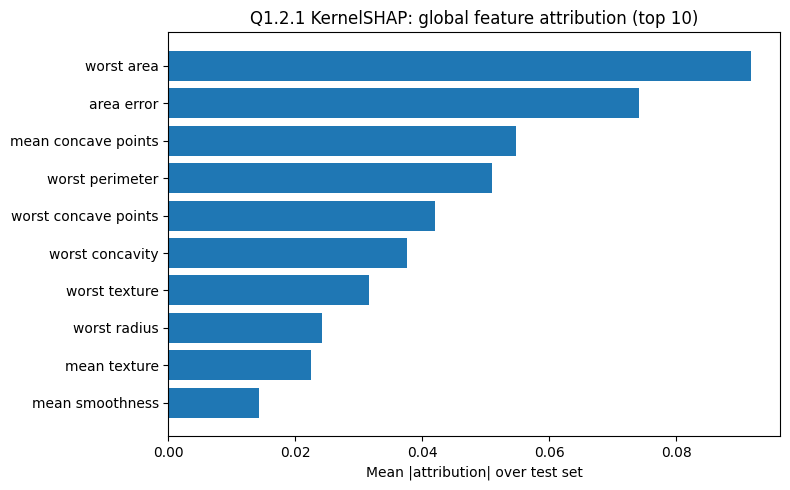

0.9649122807017544


In [70]:
np.random.seed(0)
f = lambda x: model.predict_proba(x)[:, 1]            # P(class 1)
background = shap.kmeans(X_train, 10)
kernel_explainer = KernelExplainer(f, background)

attr_kernel = kernel_explainer.shap_values(X_test)    # shape (n_test, 30)
base_kernel = kernel_explainer.expected_value         # used by the force plots
global_barplot(attr_kernel, data.feature_names, "Q1.2.1 KernelSHAP: global feature attribution (top 10)")
print(model.score(X_test, y_test))


1.2.2

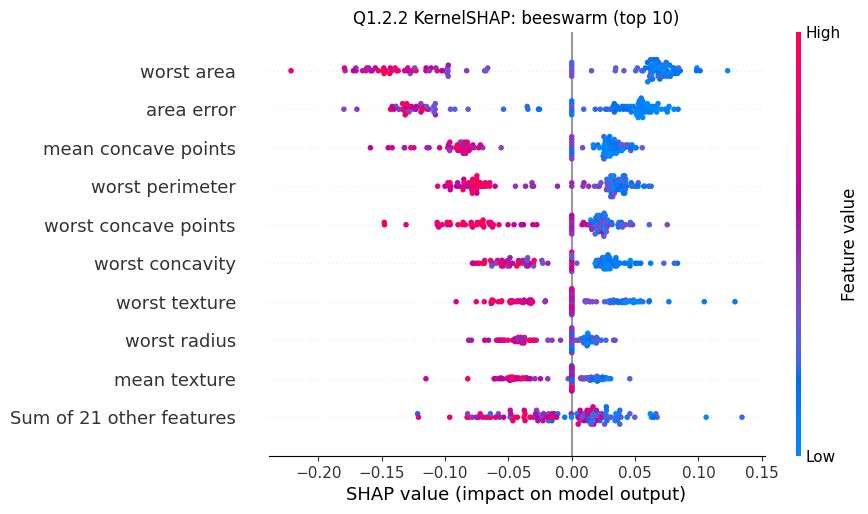

In [64]:
beeswarm(attr_kernel, X_test, data.feature_names, "Q1.2.2 KernelSHAP: beeswarm (top 10)")

1.2.3

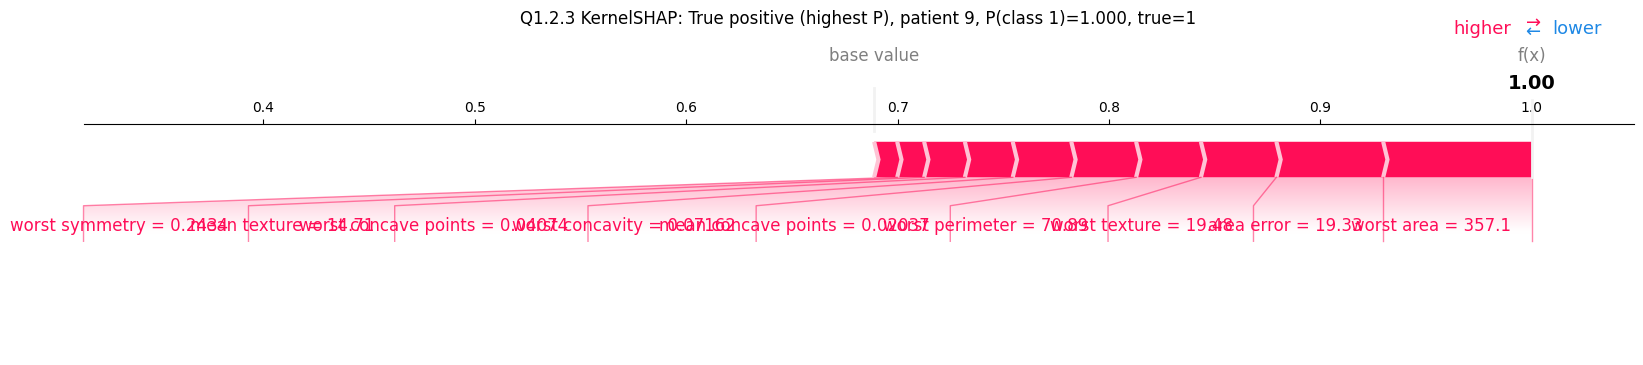

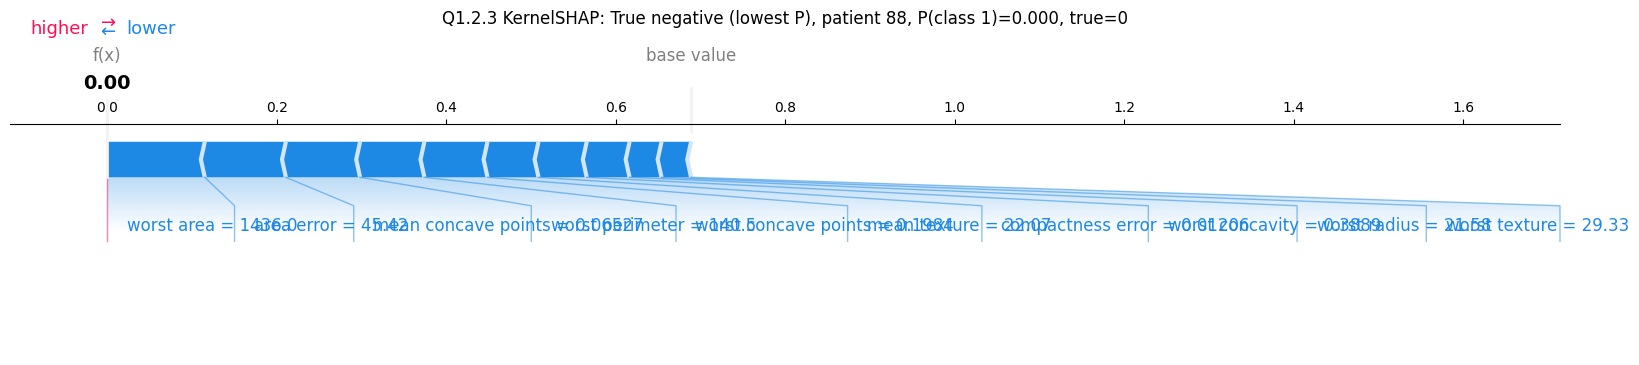

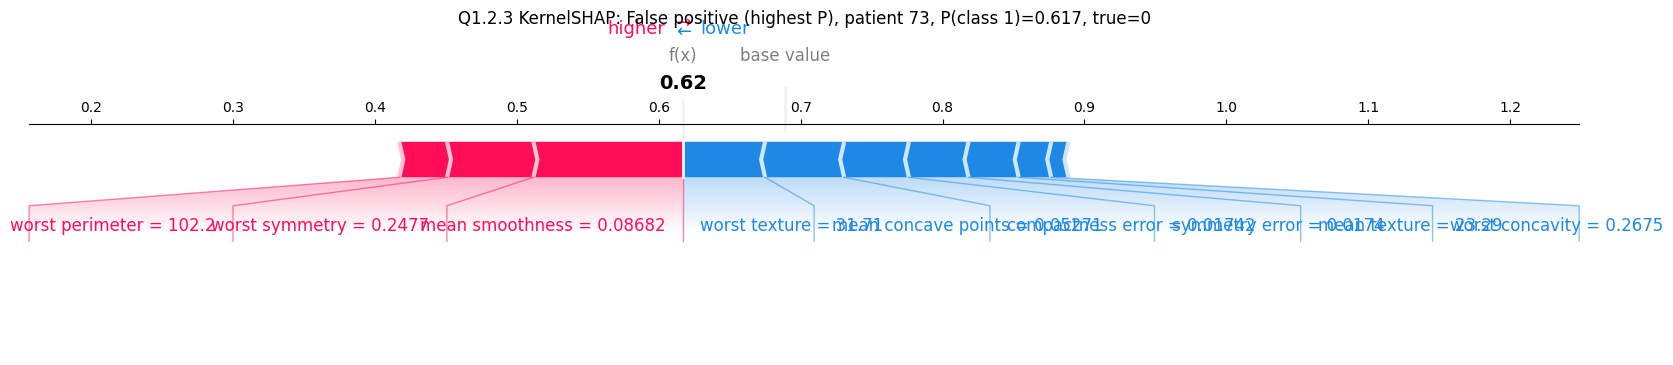

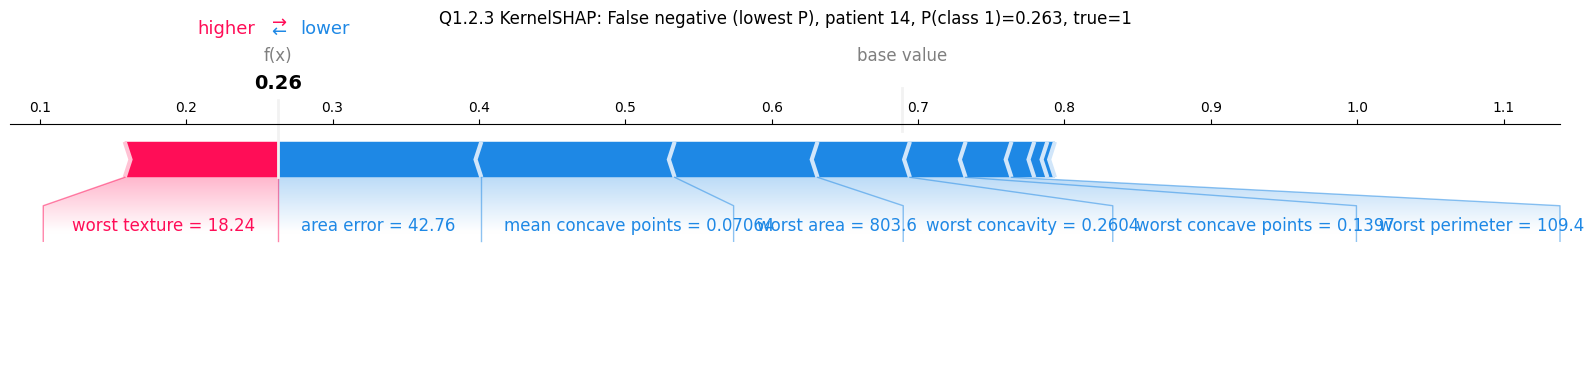

In [65]:
force_plots(base_kernel, attr_kernel, X_test, data.feature_names, "KernelSHAP")


TreeSHAP

1.2.1

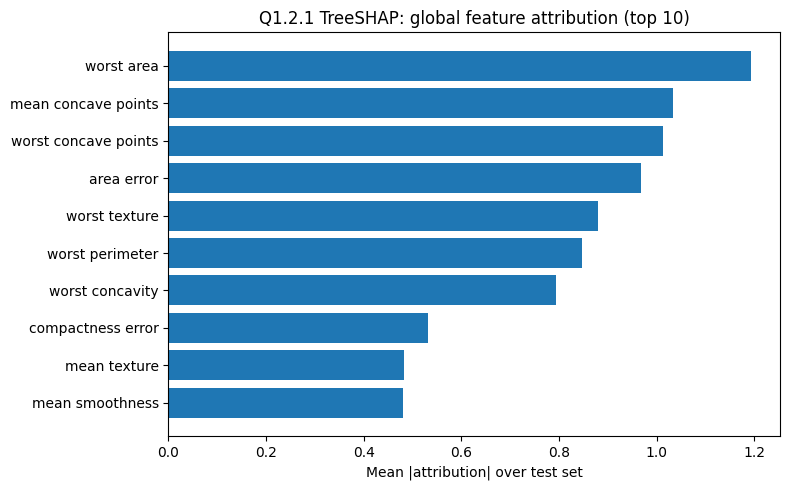

In [66]:
tree_explainer = TreeExplainer(model)

attr_tree = tree_explainer.shap_values(X_test)    # shape (n_test, 30)
base_tree = tree_explainer.expected_value         # used by the force plots
global_barplot(attr_tree, data.feature_names, "Q1.2.1 TreeSHAP: global feature attribution (top 10)")

In [ ]:
print(model.score(X_test, y_test))

0.9649122807017544


: 

1.2.2

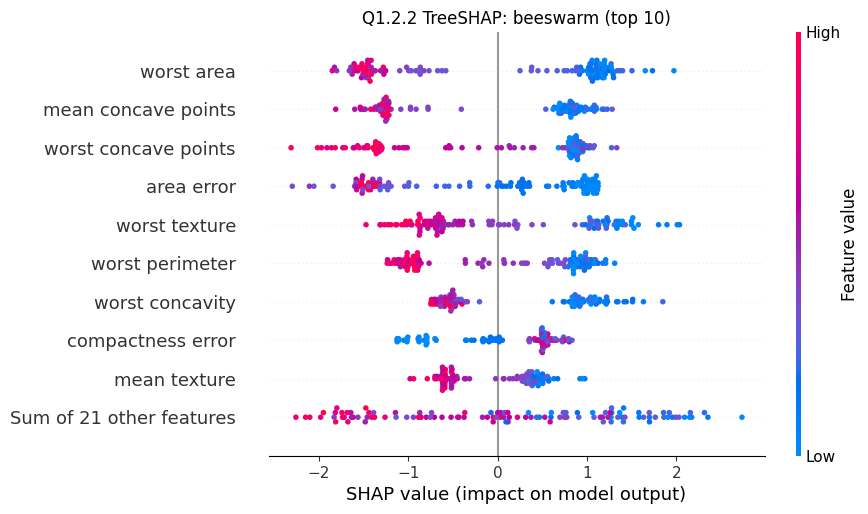

In [67]:
beeswarm(attr_tree,   X_test, data.feature_names, "Q1.2.2 TreeSHAP: beeswarm (top 10)")


1.2.3

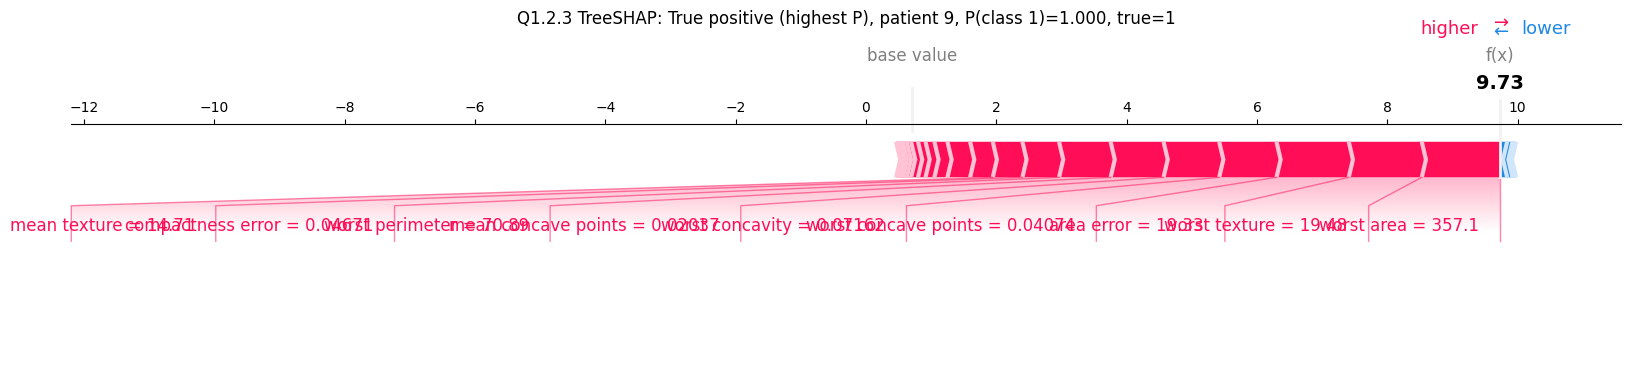

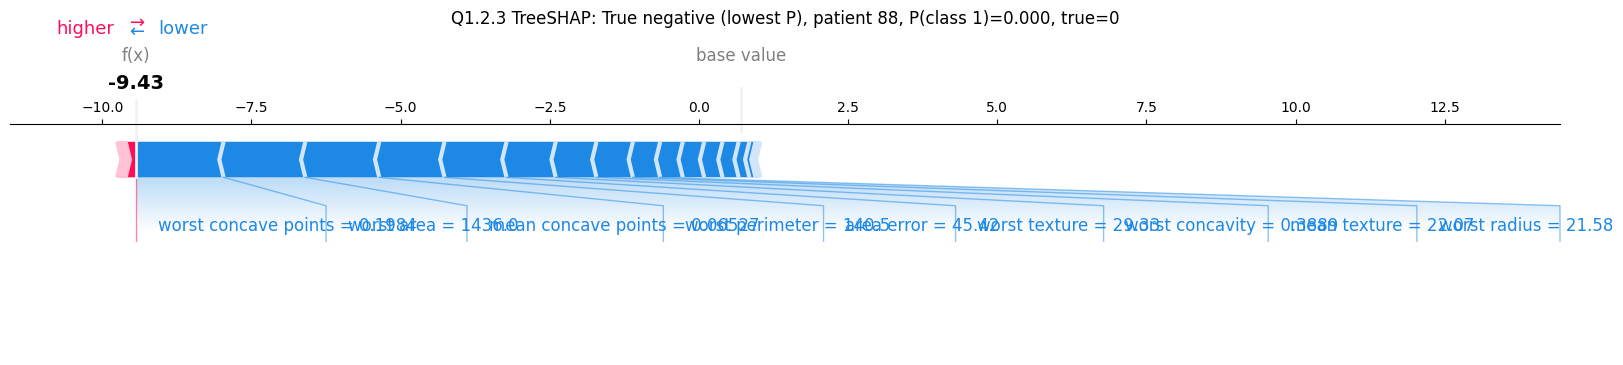

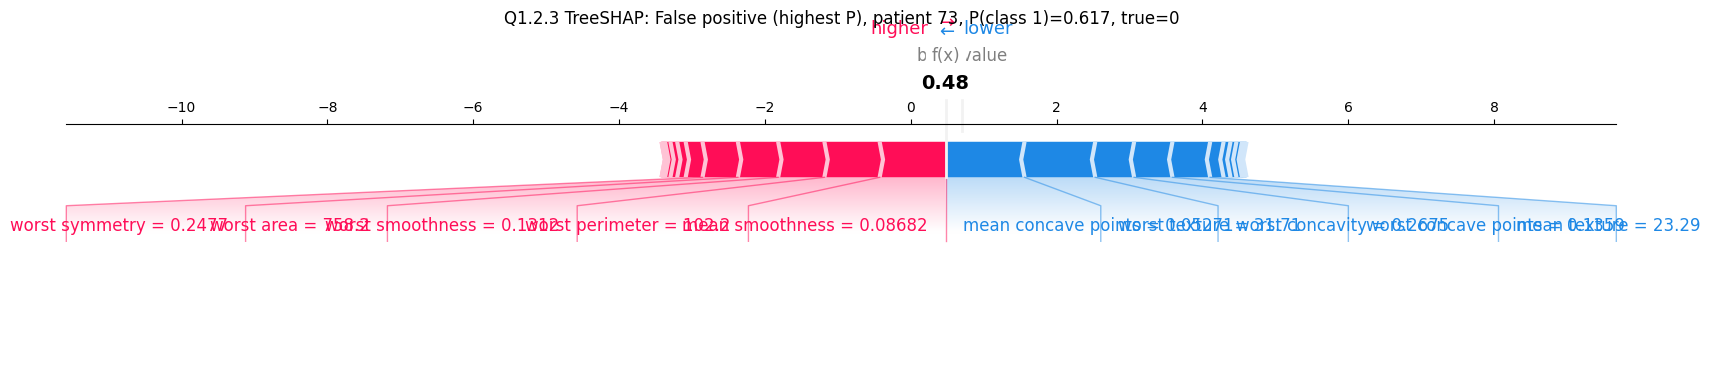

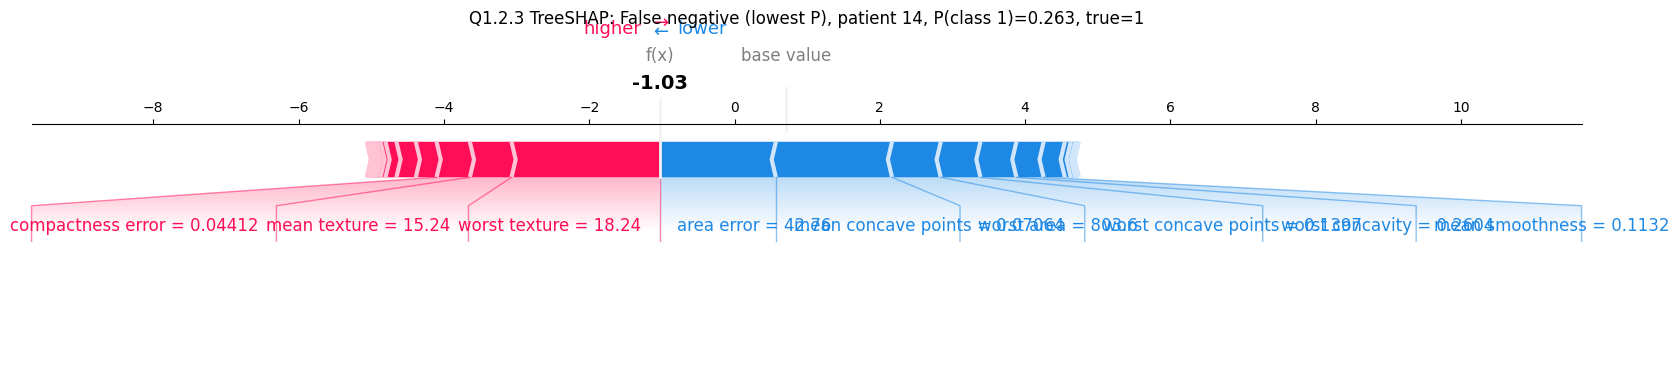

In [68]:
force_plots(base_tree, attr_tree, X_test, data.feature_names, "TreeSHAP")


1.2.4
In general, based on the horizontal bar plots, there is a large overlap in the top features between LIME, KernelSHAP and TreeSHAP: nine of the top ten features appear in all three methods (pairwise overlap is 9 to 10 out of 10). Among the top three, only worst area appears in all of them; LIME and KernelSHAP also share area error, and KernelSHAP and TreeSHAP share mean concave points. The order of prioritization of the features slightly varies between them (the rank correlations of the global attributions are between 0.92 and 0.96), but they generally keep a similar position among the top 10, indicating that there is no wide disagreement between the methods.

These top features also make sense. In all three methods, high values of features such as worst area, worst perimeter and the concavity features push the prediction toward malignant (class 0), which is expected because larger and more irregular nuclei are characteristic of malignant tumours.

This is also supported by the force plots: for true positives, the negative forces (pushing toward malignant) agree and have similar magnitude. This also applies to the positive forces in true negatives, although with slightly less agreement. In the plots, both the false positives and the false negatives are more varied, but worst area and smoothness are definite drivers in these cases. The beeswarm plots also show that, for both high and low feature values, LIME and TreeSHAP give similar attributions, whereas the negative attributions from KernelSHAP are more dispersed and only the positive ones agree with the other two methods

Question 2

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np
from ucimlrepo import fetch_ucirepo
import shap
from deeplift.visualization import viz_sequence
import matplotlib.pyplot as plt
from deeplift.dinuc_shuffle import dinuc_shuffle

In [11]:
# CNN model
class SpliceCNN(nn.Module):
    def __init__(self, input_size, num_classes, kernel_size=5):
        super(SpliceCNN, self).__init__()
        self.conv1 = nn.Conv1d(4, 8, kernel_size=kernel_size, padding=0)
        self.fc1 = nn.Linear(8 * (input_size - kernel_size + 1), 64)
        self.bn1 = nn.BatchNorm1d(64)
        self.fc2 = nn.Linear(64, num_classes)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.conv1(x)
        x = x.view(x.size(0), -1)
        x = self.relu(self.fc1(x))
        x = self.bn1(x)
        x = self.fc2(x)
        return x


# nucleotide dataset class
class SpliceDataset(Dataset):
    def __init__(self, sequences, labels):
        self.sequences = sequences
        self.labels = labels

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        seq = self.sequences[idx]
        label = self.labels[idx]
        return seq, label


# one-hot DNA encoder
def encode_dna(seq):
    encoding = {'A': [1,0,0,0], 
                'C': [0,1,0,0], 
                'G': [0,0,1,0], 
                'T': [0,0,0,1],
                'D': [1/3,0,1/3,1/3],
                'N': [1/4,1/4,1/4,1/4],
                'S': [0,1/2,1/2,0],
                'R': [1/2,0,1/2,0]}
    
    return np.array([encoding.get(base, [0,0,0,0]) for base in seq])


# load and encoder sequence data
def load_data():
    # fetch dataset
    raw_sequences = fetch_ucirepo(id=69)

    # extract DNA sequences and labels
    sequences = raw_sequences.data.features.values
    labels = raw_sequences.data.targets.values.reshape(-1,)

    le = LabelEncoder()
    y = le.fit_transform(labels)

    # to torch tensor
    encoded_sequences = np.array([encode_dna(seq) for seq in sequences])
    encoded_sequences = torch.FloatTensor(encoded_sequences).permute(0, 2, 1)
    labels = torch.LongTensor(y)

    return encoded_sequences, labels


def train_model(model, train_loader, criterion, optimizer, device):
    model.train()

    for sequences, labels in train_loader:
        optimizer.zero_grad()

        # forward pass
        sequences, labels = sequences.to(device), labels.to(device)
        outputs = model(sequences)

        loss = criterion(outputs, labels)

        # backward pass
        loss.backward()
        optimizer.step()

In [13]:
def evaluate_model(model, test_loader, device):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for sequences, labels in test_loader:
            sequences, labels = sequences.to(device), labels.to(device)
            outputs = model(sequences)

            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    classification_accuracy = correct / total

    return classification_accuracy

In [22]:
def shuffle_several_times(s):
    s = np.squeeze(s)
    return dinuc_shuffle(s, num_shufs=100)


def deeplift_analysis(model, encoded_sequences, device, labels):
    model.eval()
    with torch.no_grad():
        logits = model(encoded_sequences.to(device))
        probs = torch.softmax(logits, dim=1).cpu().numpy()   # (N, 3)
        preds = probs.argmax(axis=1)
        true = labels.numpy()

        selected = {}
        for t in range(3):
            for p in range(3):
                idx = np.where((true == t) & (preds == p))[0]
                if len(idx) == 0:
                    continue                          # empty cell, skip
                best = idx[np.argmax(probs[idx, p])]  # highest prob of the predicted class
                selected[(t, p)] = best

    fig, axes = plt.subplots(3, 3, figsize=(18,10))
    names = ["Donor", "Acceptor", "Negative"]

    for (t, p), i in selected.items():
        x = encoded_sequences[i]                           # (4, 60) tensor
        shufs = shuffle_several_times(x.numpy().T)         # (100, 60, 4)
        background = torch.FloatTensor(shufs).permute(0, 2, 1).to(device)   # (100, 4, 60)

        explainer = shap.DeepExplainer(model, background)
        sv = explainer.shap_values(x.unsqueeze(0).to(device), check_additivity=False)
        #print(np.shape(sv), type(sv))  # (1, 4, 60, 3)

        attr = np.squeeze(sv[..., p])        # (4, 60)
        scores = (attr * x.numpy()).T          # (60, 4)

        ax = axes[t, p]
        viz_sequence.plot_weights_given_ax(
            ax, scores,
            height_padding_factor=0.2,
            length_padding=1.0,
            subticks_frequency=5,
            highlight={},
        )
        ax.set_title(f"true={names[t]}, pred={names[p]}, p={probs[i,p]:.3f}")
        
    plt.tight_layout()
    plt.show()



In [27]:

def main():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # load and preprocess data
    encoded_sequences, labels = load_data()

    # split data
    X_train, X_test, y_train, y_test = train_test_split(encoded_sequences, labels, 
                                                        test_size=0.1, random_state=11)

    # dataloaders
    train_dataset = SpliceDataset(X_train, y_train)
    test_dataset = SpliceDataset(X_test, y_test)
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

    # init model
    model = SpliceCNN(input_size=60, num_classes=3, kernel_size=5).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    # train model
    num_epochs = 50
    train_accs = []
    test_accs = []
    for epoch in range(num_epochs):
        train_model(model, train_loader, criterion, optimizer, device)
        train_acc = evaluate_model(model, train_loader, device)
        test_acc = evaluate_model(model, test_loader, device)
        train_accs.append(train_acc)
        test_accs.append(test_acc)

        print(f"Epoch {epoch+1}/{num_epochs}, Train Accuracy: {train_acc:.4f}, Test Accuracy: {test_acc:.4f}")

        # plot train vs test accuracy per epoch
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, num_epochs + 1), train_accs, label="Train accuracy")
    plt.plot(range(1, num_epochs + 1), test_accs, label="Test accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title("Q2.3: CNN train and test accuracy over 50 epochs")
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"Final test accuracy: {test_accs[-1]:.4f}")

    # perform DeepLIFT analysis
    deeplift_analysis(model, X_test, device, y_test)


Epoch 1/50, Train Accuracy: 0.9669, Test Accuracy: 0.9091
Epoch 2/50, Train Accuracy: 0.9788, Test Accuracy: 0.9342
Epoch 3/50, Train Accuracy: 0.9850, Test Accuracy: 0.9404
Epoch 4/50, Train Accuracy: 0.9920, Test Accuracy: 0.9436
Epoch 5/50, Train Accuracy: 0.9955, Test Accuracy: 0.9404
Epoch 6/50, Train Accuracy: 0.9941, Test Accuracy: 0.9373
Epoch 7/50, Train Accuracy: 0.9958, Test Accuracy: 0.9342
Epoch 8/50, Train Accuracy: 0.9979, Test Accuracy: 0.9373
Epoch 9/50, Train Accuracy: 0.9993, Test Accuracy: 0.9342
Epoch 10/50, Train Accuracy: 0.9990, Test Accuracy: 0.9404
Epoch 11/50, Train Accuracy: 0.9986, Test Accuracy: 0.9248
Epoch 12/50, Train Accuracy: 0.9993, Test Accuracy: 0.9342
Epoch 13/50, Train Accuracy: 0.9993, Test Accuracy: 0.9436
Epoch 14/50, Train Accuracy: 0.9990, Test Accuracy: 0.9467
Epoch 15/50, Train Accuracy: 0.9993, Test Accuracy: 0.9404
Epoch 16/50, Train Accuracy: 0.9993, Test Accuracy: 0.9310
Epoch 17/50, Train Accuracy: 0.9993, Test Accuracy: 0.9373
Epoch 

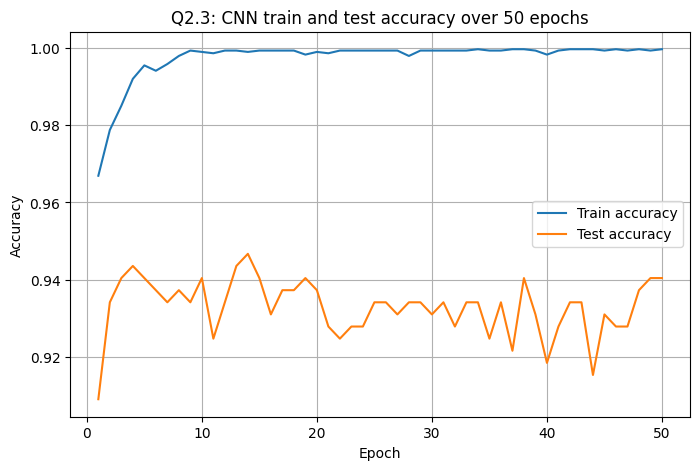

Final test accuracy: 0.9404


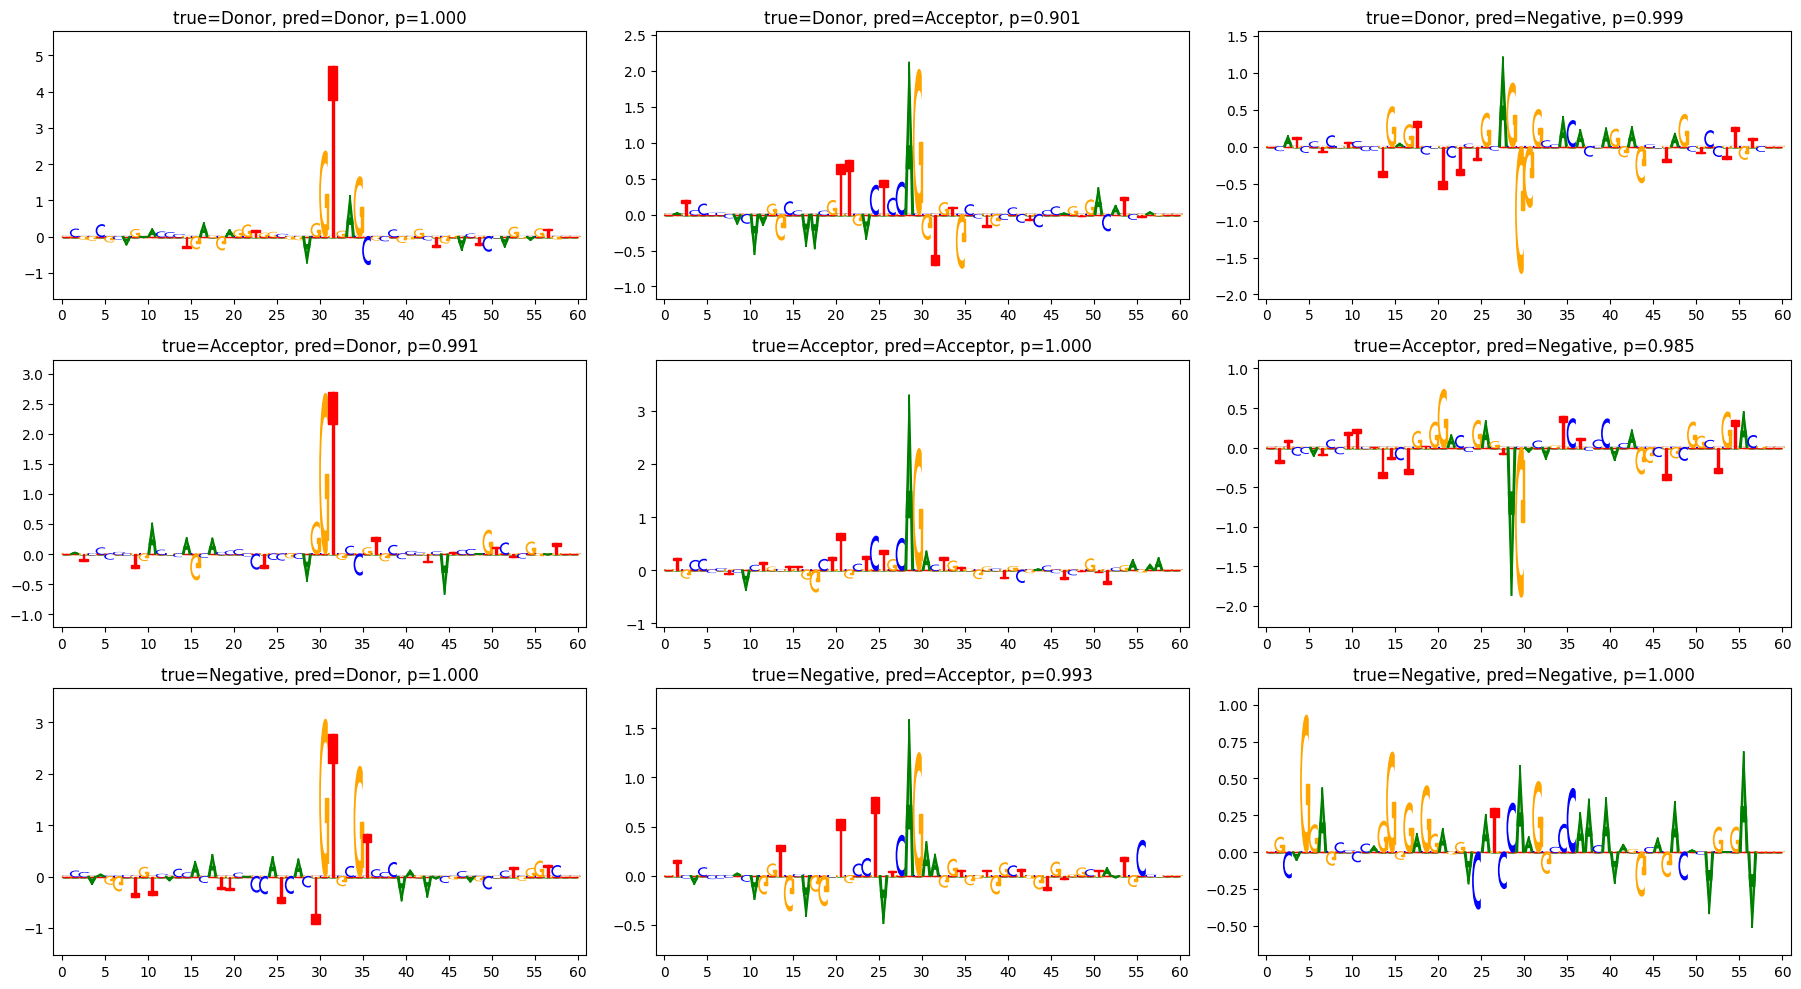

In [28]:
main()

The center diagonal of the above plot corresponds to the expected result. From the predicted and true donor plot, we can see that the most prominent nucleotides that pushes towards the model are GT, which is the canonical donor site. It is worth mentioning that this is followed in prominence by a nearby AG, which matches the extended donor consensus (GTRAGT), where an AG appears a few positions downstream of the GT. In the case of predicted and true acceptor site, there's more certainty, as in this case the most prominent nucleotide pair is much more prominent than the others. This prediction indeed matches the canonical sequence, as is AG. Moreover, what we see in the negative true and prediction site is what's expected. There's no single canonical sequence for the negative label, as they are simple any sequence that does not code for a donor or acceptor site.

In the case of the mistaken predictions (off-diagonal plots), it is clear from the prominence in the sequence why the model labeled each of the examples as such. For the mistaken donor sites, GT is still the most prominent sequence. This corresponds to what happens to the acceptor sites with the AG sequence. The mistakenly predicted Negative cases are the opposite: when it was truly a Donor site, the GT sequence wasn't prominent enough. Similarly, in the truly Acceptor site, the AG  appears with negative attribution, meaning that these nucleotides pushed the model away from the Negative prediction. The model still predicted Negative, likely because the contributions from the rest of the sequence outweighed them.

These features make sense according to the literature. Donor (5′) and acceptor (3′) splice sites contain a nearly invariant GT and AG, respectively, within a longer conserved context (Shapiro & Senapathy, 1987). Because GT and AG occur far more often in the genome than real splice sites, the surrounding context is needed to tell them apart, which explains why a GT or AG at the junction can fool the model (some of these cases may also be label noise). Splicing is additionally regulated by features beyond the canonical sequences, including positions deeper into introns (Barash et al., 2010).


Code debugged using Claude